# Lab 5: "Shout STOP!" — Building the Brain of a Voice Emergency Stop

### Objective & Context
We begin by preparing a balanced dataset containing three classes:
1. **`stop`**: Clips from the Google Speech Commands `stop` directory.
2. **`_unknown_`**: Balanced randomly chosen clips from other directory classes.
3. **`_silence_`**: Hand-crafted 1-second background-noise clips.

To ensure our evaluation is rigorous for safety on a real factory floor with new employees, we perform a **speaker-wise split (80/10/10)**, meaning the model's test evaluation uses voices it has never heard before.

In [ ]:
import os
import re
import glob
import random
import tarfile
import urllib.request
import numpy as np
import tensorflow as tf

# Set random seeds for reproducibility
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# 1. Download Mini Speech Commands
DATASET_URL = 'http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
zip_path = tf.keras.utils.get_file('mini_speech_commands.zip', origin=DATASET_URL, extract=True, cache_dir='.')

# Keras extracts the zip inside a directory named '{filename}_extracted'
data_dir = os.path.join(os.path.dirname(zip_path), 'mini_speech_commands_extracted', 'mini_speech_commands')

# 2. Extract speaker ID from filename
def get_speaker_id(file_path):
    filename = os.path.basename(file_path)
    match = re.match(r'([a-f0-9]+)_nohash_', filename)
    return match.group(1) if match else filename

# 3. Collect "stop" and "unknown" files
words = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))]
stop_files = glob.glob(os.path.join(data_dir, 'stop', '*.wav'))
target_count = len(stop_files)

other_files = []
for w in words:
    if w not in ['stop', '_background_noise_']:
        other_files.extend(glob.glob(os.path.join(data_dir, w, '*.wav')))

random.shuffle(other_files)
unknown_files = other_files[:target_count]

# 4. Generate "_silence_" files from background noise
noise_dir = os.path.join(data_dir, '_background_noise_')
noise_files = glob.glob(os.path.join(noise_dir, '*.wav'))
silence_clips = []

if noise_files:
    raw_noises = []
    for nf in noise_files:
        audio_binary = tf.io.read_file(nf)
        audio, _ = tf.audio.decode_wav(audio_binary)
        raw_noises.append(audio.numpy().flatten())
    combined_noise = np.concatenate(raw_noises)

    for i in range(target_count):
        idx = random.randint(0, len(combined_noise) - 16000)
        silence_clips.append(combined_noise[idx:idx + 16000])
else:
    # Synthesised comfortable background ambient noise
    for _ in range(target_count):
        ambient = np.random.normal(0, 0.005, 16000).astype(np.float32)
        silence_clips.append(ambient)

# 5. Split by Speaker ID (80 / 10 / 10)
def speaker_split(file_list, val_ratio=0.10, test_ratio=0.10):
    speaker_map = {}
    for f in file_list:
        spk = get_speaker_id(f)
        speaker_map.setdefault(spk, []).append(f)

    speakers = list(speaker_map.keys())
    random.shuffle(speakers)

    n_total = len(speakers)
    n_val = int(n_total * val_ratio)
    n_test = int(n_total * test_ratio)

    val_spks = set(speakers[:n_val])
    test_spks = set(speakers[n_val:n_val + n_test])
    train_spks = set(speakers[n_val + n_test:])

    train, val, test = [], [], []
    for spk, files in speaker_map.items():
        if spk in val_spks:
            val.extend(files)
        elif spk in test_spks:
            test.extend(files)
        else:
            train.extend(files)
    return train, val, test

stop_tr, stop_va, stop_te = speaker_split(stop_files)
unk_tr, unk_va, unk_te = speaker_split(unknown_files)

# Silence split
n_sil_val = int(target_count * 0.10)
n_sil_test = int(target_count * 0.10)
sil_va = silence_clips[:n_sil_val]
sil_te = silence_clips[n_sil_val:n_sil_val + n_sil_test]
sil_tr = silence_clips[n_sil_val + n_sil_test:]

### Audio Preprocessing & MFCC Feature Extraction

To feed the audio to our lightweight neural network, we transform raw amplitude waveforms into the frequency domain.
We process every 16 kHz clip to exactly 1 second, framing with a **30 ms window** and a **20 ms hop (stride)**. This creates a 49x10 MFCC representation.

* **Why do 'stop' and 'go' look different?**
  The phoneme "st" in "stop" is an unvoiced fricative/plosive showing high-frequency, noisy energy distribution (concentrated at the top of spectrograms and early frames), whereas "go" begins with a voiced velar plosive, followed by a resonant vowel sound containing strong low-frequency harmonic bands (formants) that span late frames.

In [ ]:
import matplotlib.pyplot as plt

def compute_mfcc(audio, sample_rate=16000, num_mfcc=10):
    # Ensure fixed 1-second length (16000 samples)
    audio = tf.convert_to_tensor(audio, dtype=tf.float32)
    audio = audio[:16000]
    padding = tf.maximum(0, 16000 - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])

    # STFT parameters: 30 ms window (480), 20 ms hop (320)
    stft = tf.signal.stft(audio, frame_length=480, frame_step=320, fft_length=512)
    spectrogram = tf.abs(stft)

    # 40-band Mel-scale filterbank between 20 Hz and 4000 Hz
    num_spectrogram_bins = stft.shape[-1]
    linear_to_mel_matrix = tf.signal.linear_to_mel_weight_matrix(
        num_mel_bins=40,
        num_spectrogram_bins=num_spectrogram_bins,
        sample_rate=sample_rate,
        lower_edge_hertz=20.0,
        upper_edge_hertz=4000.0
    )
    mel_spectrogram = tf.tensordot(spectrogram, linear_to_mel_matrix, 1)
    mel_spectrogram.set_shape(spectrogram.shape[:-1].concatenate(linear_to_mel_matrix.shape[-1:]))
    log_mel = tf.math.log(mel_spectrogram + 1e-6)

    # DCT to obtain 10 MFCC coefficients (shape: 49, 10)
    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :num_mfcc]
    return audio, spectrogram, mfcc

### Designing the DS-CNN (Depthwise Separable CNN) KWS Brain

Standard 2D convolutions are too resource-heavy for microcontrollers with <100 KB memory limit.
Here, we implement a **DS-CNN (Depthwise Separable Convolutional Neural Network)**. By splitting standard convolutions into depthwise (spatial filtering) and pointwise (channel mixing), we drastically reduce parameters while retaining high accuracy.

In [ ]:
def build_ds_cnn(input_shape=(49, 10, 1), num_classes=3):
    inputs = tf.keras.Input(shape=input_shape)

    # Initial standard Conv2D
    x = tf.keras.layers.Conv2D(32, kernel_size=(3, 3), strides=(1, 1), padding='same', use_bias=False)(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)

    # DS-CNN Block 1
    x = tf.keras.layers.DepthwiseConv2D(kernel_size=(3, 3), strides=(1, 1), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.Conv2D(48, kernel_size=(1, 1), strides=(1, 1), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)

    # DS-CNN Block 2
    x = tf.keras.layers.DepthwiseConv2D(kernel_size=(3, 3), strides=(2, 1), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    x = tf.keras.layers.Conv2D(64, kernel_size=(1, 1), strides=(1, 1), padding='same', use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)

    # Classification Head
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.2)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs=inputs, outputs=outputs, name="DS_CNN_KWS")

model = build_ds_cnn()
model.summary()

Model: "DS_CNN_KWS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 49, 10, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 49, 10, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 49, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 49, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_2              │ (None, 49, 10, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 49, 10, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 49, 10, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 49, 10, 48)     │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 49, 10, 48)     │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 49, 10, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_3              │ (None, 25, 10, 48)     │           432 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 25, 10, 48)     │           192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_8 (ReLU)                  │ (None, 25, 10, 48)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 10, 64)     │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 25, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_9 (ReLU)                  │ (None, 25, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,707 (26.20 KB)

 Trainable params: 6,259 (24.45 KB)

 Non-trainable params: 448 (1.75 KB)

### Training Pipeline with Data Augmentation

To make our model robust to noisy industrial environments and variations in when workers shout relative to the microphone, we train using online augmentations:
1. **Time Shift**: Randomly rolls the audio signal.
2. **Background Noise injection**: Synthesises industrial noise patterns.

In [ ]:
import numpy as np
import tensorflow as tf

# 1. Helper to load audio and pad/trim to 1 second
def load_wav(filepath):
    audio_binary = tf.io.read_file(filepath)
    audio, _ = tf.audio.decode_wav(audio_binary)
    audio = tf.squeeze(audio, axis=-1)
    padding = tf.maximum(0, 16000 - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])
    return audio[:16000].numpy()

# 2. Load training and validation audio arrays
print("Loading audio files... (this might take a few seconds)")
stop_tr_audio = [load_wav(f) for f in stop_tr]
stop_va_audio = [load_wav(f) for f in stop_va]

unk_tr_audio = [load_wav(f) for f in unk_tr]
unk_va_audio = [load_wav(f) for f in unk_va]

# 3. Combine into final train and val lists
train_data = stop_tr_audio + unk_tr_audio + sil_tr
train_labels = [0] * len(stop_tr_audio) + [1] * len(unk_tr_audio) + [2] * len(sil_tr)

val_data = stop_va_audio + unk_va_audio + sil_va
val_labels = [0] * len(stop_va_audio) + [1] * len(unk_va_audio) + [2] * len(sil_va)

# 4. Define feature extraction and augmentation
def compute_mfcc(audio, sample_rate=16000, num_mfcc=10):
    audio = tf.convert_to_tensor(audio, dtype=tf.float32)
    audio = audio[:16000]
    padding = tf.maximum(0, 16000 - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])

    stft = tf.signal.stft(audio, frame_length=480, frame_step=320, fft_length=512)
    spectrogram = tf.abs(stft)

    linear_to_mel_matrix = tf.signal.linear_to_mel_weight_matrix(
        num_mel_bins=40, num_spectrogram_bins=stft.shape[-1],
        sample_rate=sample_rate, lower_edge_hertz=20.0, upper_edge_hertz=4000.0)

    mel_spectrogram = tf.tensordot(spectrogram, linear_to_mel_matrix, 1)
    mel_spectrogram.set_shape(spectrogram.shape[:-1].concatenate(linear_to_mel_matrix.shape[-1:]))
    log_mel = tf.math.log(mel_spectrogram + 1e-6)

    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :num_mfcc]
    return audio, spectrogram, mfcc

def augment_audio(audio):
    shift = tf.random.uniform([], -1600, 1600, dtype=tf.int32)
    audio = tf.roll(audio, shift, axis=0)
    noise = tf.random.normal(shape=tf.shape(audio), mean=0.0, stddev=0.015, dtype=tf.float32)
    return audio + noise

def preprocess_train(audio, label):
    audio = augment_audio(audio)
    _, _, mfcc = compute_mfcc(audio)
    return tf.expand_dims(mfcc, -1), label

def preprocess_val(audio, label):
    _, _, mfcc = compute_mfcc(audio)
    return tf.expand_dims(mfcc, -1), label

def create_dataset(audio_list, label_list, is_training=True):
    ds = tf.data.Dataset.from_tensor_slices((audio_list, label_list))
    if is_training:
        ds = ds.shuffle(buffer_size=2000)
        ds = ds.map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

# 5. Create datasets
print("Building tf.data pipelines...")
train_ds = create_dataset(train_data, train_labels, is_training=True)
val_ds = create_dataset(val_data, val_labels, is_training=False)

# 6. Compile and Train
print("Starting training...")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)
]

history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Loading audio files... (this might take a few seconds)
Building tf.data pipelines...
Starting training...
Epoch 1/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 12s 47ms/step - accuracy: 0.5925 - loss: 0.8538 - val_accuracy: 0.5000 - val_loss: 1.0758 - learning_rate: 0.0010
Epoch 2/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.7471 - loss: 0.5898 - val_accuracy: 0.5888 - val_loss: 0.9166 - learning_rate: 0.0010
Epoch 3/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.7992 - loss: 0.4847 - val_accuracy: 0.3322 - val_loss: 0.9603 - learning_rate: 0.0010
Epoch 4/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.8304 - loss: 0.4113 - val_accuracy: 0.3783 - val_loss: 2.6146 - learning_rate: 0.0010
Epoch 5/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8421 - loss: 0.3863 - val_accuracy: 0.3553 - val_loss: 5.5104 - learning_rate: 0.0010
Epoch 6/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.8608 - loss: 0.3497 - val_accuracy: 0.3750 - val_loss: 9.1547 - learning_

### Safety Check & Metrics Evaluation

We evaluate the model on the test speaker partition (unseen voices).
We extract a complete **Confusion Matrix** to evaluate the safety officer's critical targets:
1. **Misses (False Negatives)**: The model fails to recognize 'stop' (Highly Dangerous—the conveyor belt keeps running).
2. **False Alarms (False Positives)**: Other words are misclassified as 'stop' (Costly—stops production lines needlessly).

In [ ]:
import numpy as np
import tensorflow as tf
from sklearn.metrics import confusion_matrix

# 1. Define missing feature extraction and pipeline functions
def compute_mfcc(audio, sample_rate=16000, num_mfcc=10):
    audio = tf.convert_to_tensor(audio, dtype=tf.float32)
    audio = audio[:16000]
    padding = tf.maximum(0, 16000 - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])

    stft = tf.signal.stft(audio, frame_length=480, frame_step=320, fft_length=512)
    spectrogram = tf.abs(stft)

    linear_to_mel_matrix = tf.signal.linear_to_mel_weight_matrix(
        num_mel_bins=40, num_spectrogram_bins=stft.shape[-1],
        sample_rate=sample_rate, lower_edge_hertz=20.0, upper_edge_hertz=4000.0)

    mel_spectrogram = tf.tensordot(spectrogram, linear_to_mel_matrix, 1)
    mel_spectrogram.set_shape(spectrogram.shape[:-1].concatenate(linear_to_mel_matrix.shape[-1:]))
    log_mel = tf.math.log(mel_spectrogram + 1e-6)

    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :num_mfcc]
    return audio, spectrogram, mfcc

def augment_audio(audio):
    shift = tf.random.uniform([], -1600, 1600, dtype=tf.int32)
    audio = tf.roll(audio, shift, axis=0)
    noise = tf.random.normal(shape=tf.shape(audio), mean=0.0, stddev=0.015, dtype=tf.float32)
    return audio + noise

def preprocess_train(audio, label):
    audio = augment_audio(audio)
    _, _, mfcc = compute_mfcc(audio)
    return tf.expand_dims(mfcc, -1), label

def preprocess_val(audio, label):
    _, _, mfcc = compute_mfcc(audio)
    return tf.expand_dims(mfcc, -1), label

def create_dataset(audio_list, label_list, is_training=True):
    ds = tf.data.Dataset.from_tensor_slices((audio_list, label_list))
    if is_training:
        ds = ds.shuffle(buffer_size=2000)
        ds = ds.map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        ds = ds.map(preprocess_val, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

# 2. Load audio files into uniform arrays
def load_wav(filepath):
    audio_binary = tf.io.read_file(filepath)
    audio, _ = tf.audio.decode_wav(audio_binary)
    audio = tf.squeeze(audio, axis=-1)
    padding = tf.maximum(0, 16000 - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])
    return audio[:16000].numpy()

# Load all splits
stop_tr_audio = [load_wav(f) for f in stop_tr]
stop_va_audio = [load_wav(f) for f in stop_va]
stop_te_audio = [load_wav(f) for f in stop_te]

unk_tr_audio = [load_wav(f) for f in unk_tr]
unk_va_audio = [load_wav(f) for f in unk_va]
unk_te_audio = [load_wav(f) for f in unk_te]

# 3. Combine uniform arrays and labels
test_data = stop_te_audio + unk_te_audio + sil_te
test_labels = [0] * len(stop_te_audio) + [1] * len(unk_te_audio) + [2] * len(sil_te)

# 4. Create the test dataset
test_ds = create_dataset(test_data, test_labels, is_training=False)

# 5. Extract ground truth and get predictions
y_test = np.concatenate([y for x, y in test_ds], axis=0)
y_pred = np.argmax(model.predict(test_ds), axis=1)

# 6. Calculate metrics
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
stop_true_total = np.sum(cm[0, :])
stop_detected = cm[0, 0]

misses = stop_true_total - stop_detected
false_alarms = cm[1, 0] + cm[2, 0]

print(f"Safety Officer Metrics:")
print(f"- Unseen Speaker Accuracy: {np.trace(cm) / np.sum(cm) * 100:.2f}%")
print(f"- Misses (Belt keeps running): {misses} / {stop_true_total}")
print(f"- False Alarms (Line stops needlessly): {false_alarms}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step
Safety Officer Metrics:
- Unseen Speaker Accuracy: 59.80%
- Misses (Belt keeps running): 65 / 100
- False Alarms (Line stops needlessly): 31


### Deployment Preparation: INT8 TFLite Quantization

We convert our trained TensorFlow model to fully quantized INT8 TFLite representation using representative calibration datasets. This shrinks the footprint to ~45-50 KB to fit the microcontroller hardware constraints.

In [ ]:
import json
import tensorflow as tf

# 1. Build the missing validation dataset
val_data = stop_va_audio + unk_va_audio + sil_va
val_labels = [0] * len(stop_va_audio) + [1] * len(unk_va_audio) + [2] * len(sil_va)
val_ds = create_dataset(val_data, val_labels, is_training=False)

# 2. Representative calibration dataset from validation features
def representative_data_gen():
    for mfcc_batch, _ in val_ds.take(100):
        yield [mfcc_batch]

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_int8_model = converter.convert()

# Save binary model
with open('kws_int8.tflite', 'wb') as f:
    f.write(tflite_int8_model)

# Float32 model for comparison
float_converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float_model = float_converter.convert()
with open('kws_float.tflite', 'wb') as f:
    f.write(tflite_float_model)

# Export Lab 6 deployment configuration
config = {
    "project": "SafeLine Voice E-Stop",
    "sample_rate": 16000,
    "clip_duration_ms": 1000,
    "window_size_ms": 30,
    "window_stride_ms": 20,
    "feature_bins": 10,
    "time_frames": 49,
    "classes": ["stop", "_unknown_", "_silence_"],
    "stop_threshold": 0.35,
    "model_file": "kws_int8.tflite"
}

with open('kws_config.json', 'w') as f:
    json.dump(config, f, indent=4)

Saved artifact at '/tmp/tmplkfyv4m8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 10, 1), dtype=tf.float32, name='keras_tensor_19')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  136959282254992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941397968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941393168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941398160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941396048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941388944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941402960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941403920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941403536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941393552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1369559414043

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved artifact at '/tmp/tmp3rvp2ftt'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 49, 10, 1), dtype=tf.float32, name='keras_tensor_19')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  136959282254992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941397968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941393168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941398160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941396048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941388944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941402960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941403920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941403536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136955941393552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1369559414043

# Lab 6: Field Trial — Streaming Voice E-Stop Deployment

### Hardware Specification Verification

We verify the hardware deployment targets by loading our quantized INT8 TFLite model and checking its metadata, quantization scales, and shapes.

In [ ]:
import os
import json
import time
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import collections

# 1. Load the configuration exported from Lab 5
with open('kws_config.json', 'r') as f:
    config = json.load(f)

print("Configuration loaded:", config)

# 2. Load the INT8 TFLite model
interpreter = tf.lite.Interpreter(model_path=config["model_file"])
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

input_shape = input_details['shape']
input_dtype = input_details['dtype']
input_scale, input_zero_point = input_details['quantization']

output_scale, output_zero_point = output_details['quantization']

print("\n--- Hardware Team Specifications ---")
print(f"Input Shape: {input_shape}")
print(f"Input Type:  {input_dtype}")
print(f"Quantisation Scale: {input_scale}, Zero Point: {input_zero_point}")
print(f"Output Classes: {config['classes']}")

Configuration loaded: {'project': 'SafeLine Voice E-Stop', 'sample_rate': 16000, 'clip_duration_ms': 1000, 'window_size_ms': 30, 'window_stride_ms': 20, 'feature_bins': 10, 'time_frames': 49, 'classes': ['stop', '_unknown_', '_silence_'], 'stop_threshold': 0.35, 'model_file': 'kws_int8.tflite'}

--- Hardware Team Specifications ---
Input Shape: [ 1 49 10  1]
Input Type:  <class 'numpy.int8'>
Quantisation Scale: 0.5966644287109375, Zero Point: 79
Output Classes: ['stop', '_unknown_', '_silence_']


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


### Bench Test using Dataset Clips

We conduct a bench test using 15 random unseen validation dataset clips to verify the quantized model's accuracy, inputs, and outputs.

In [ ]:
def compute_mfcc_live(audio, sample_rate=16000):
    audio = tf.convert_to_tensor(audio, dtype=tf.float32)
    padding = tf.maximum(0, 16000 - tf.shape(audio)[0])
    audio = tf.pad(audio, [[0, padding]])[:16000]

    stft = tf.signal.stft(audio, frame_length=480, frame_step=320, fft_length=512)
    spectrogram = tf.abs(stft)

    linear_to_mel_matrix = tf.signal.linear_to_mel_weight_matrix(
        num_mel_bins=40, num_spectrogram_bins=stft.shape[-1],
        sample_rate=sample_rate, lower_edge_hertz=20.0, upper_edge_hertz=4000.0)

    mel_spectrogram = tf.tensordot(spectrogram, linear_to_mel_matrix, 1)
    mel_spectrogram.set_shape(spectrogram.shape[:-1].concatenate(linear_to_mel_matrix.shape[-1:]))
    log_mel = tf.math.log(mel_spectrogram + 1e-6)

    mfcc = tf.signal.mfccs_from_log_mel_spectrograms(log_mel)[..., :10]
    return tf.expand_dims(mfcc, -1)

def run_tflite_inference(audio_array):
    # 1. Feature extraction
    t0 = time.time()
    mfcc = compute_mfcc_live(audio_array)
    mfcc_time = (time.time() - t0) * 1000

    # 2. Quantise input
    mfcc_quantised = np.round((mfcc.numpy() / input_scale) + input_zero_point).astype(np.int8)
    mfcc_quantised = np.expand_dims(mfcc_quantised, axis=0) # Add batch dimension

    # 3. Invoke interpreter
    t1 = time.time()
    interpreter.set_tensor(input_details['index'], mfcc_quantised)
    interpreter.invoke()
    output_quantised = interpreter.get_tensor(output_details['index'])[0]
    inference_time = (time.time() - t1) * 1000

    # 4. Dequantise output
    probabilities = (output_quantised.astype(np.float32) - output_zero_point) * output_scale

    return probabilities, mfcc_time, inference_time

# Example test on a few random clips from Lab 5's test_ds (if available in memory)
print(f"{'True Label':<12} | {'Predicted':<12} | {'Confidence':<10}")
print("-" * 40)
for i in range(5):
    test_audio = test_data[i] # Pulling from Lab 5 variables
    probs, _, _ = run_tflite_inference(test_audio)
    pred_idx = np.argmax(probs)
    print(f"{config['classes'][test_labels[i]]:<12} | {config['classes'][pred_idx]:<12} | {probs[pred_idx]*100:.1f}%")

True Label   | Predicted    | Confidence
----------------------------------------
stop         | stop         | 39.5%
stop         | stop         | 40.2%
stop         | stop         | 37.5%
stop         | stop         | 37.5%
stop         | _unknown_    | 34.0%


### Real-time Voice Audio Acquisition

This utility records live voice commands using the browser microphone, resampling them to 16 kHz mono for processing.

In [ ]:
from IPython.display import HTML, Audio
from google.colab.output import eval_js
from base64 import b64decode
import scipy.io.wavfile as wav

AUDIO_HTML = """
<script>
var my_div = document.createElement("DIV");
var my_p = document.createElement("P");
var my_btn = document.createElement("BUTTON");
var t = document.createTextNode("Press to start recording");

my_btn.appendChild(t);
my_div.appendChild(my_btn);
document.body.appendChild(my_div);

var base64data = 0;
var reader;
var recorder, gumStream;
var recordButton = my_btn;

var handleSuccess = function(stream) {
  gumStream = stream;
  var options = {
    mimeType : 'audio/webm;codecs=opus'
  };
  recorder = new MediaRecorder(stream, options);
  recorder.ondataavailable = function(e) {
    var url = URL.createObjectURL(e.data);
    var preview = document.createElement('audio');
    preview.controls = true;
    preview.src = url;
    document.body.appendChild(preview);

    reader = new FileReader();
    reader.readAsDataURL(e.data);
    reader.onloadend = function() {
      base64data = reader.result;
    }
  };
  recorder.start();
  };

recordButton.innerText = "Recording... press to stop";

navigator.mediaDevices.getUserMedia({audio: true}).then(handleSuccess);

function toggleRecording() {
  if (recorder && recorder.state == "recording") {
      recorder.stop();
      gumStream.getAudioTracks()[0].stop();
      recordButton.innerText = "Saving the recording... pls wait!"
  }
}

function sleep(ms) {
  return new Promise(resolve => setTimeout(resolve, ms));
}

var data = new Promise(resolve=>{
recordButton.onclick = ()=>{
toggleRecording()
sleep(2000).then(() => {
  resolve(base64data.toString())
});
}
});

</script>
"""

def record_audio(filename="live_trial.wav"):
    display(HTML(AUDIO_HTML))
    data = eval_js("data")
    binary = b64decode(data.split(',')[1])

    with open("temp.webm", 'wb') as f:
        f.write(binary)

    # Convert webm to 16kHz mono wav using ffmpeg
    os.system(f"ffmpeg -i temp.webm -ac 1 -ar 16000 {filename} -y")
    print(f"Saved to {filename}")

# Run this to record a 15-second "work shift" (talk, pause, shout "stop" a few times)
record_audio("work_shift.wav")

Saved to work_shift.wav


### Always-Listening Continuous Streaming Inference

We implement the core streaming engine using a **1-second sliding window** sliding forward by **100 ms strides**.
* **Smoothing**: We calculate a 3-frame moving average of predictions to prevent flickering.
* **Refractory Period**: Once triggered, a 1-second lockout is initiated so one shout results in exactly one stop event.


--- Factory Floor Live Feed ---
[1.3s] 🛑 BELT STOPPED (Confidence: 50.7%)
[2.3s] 🛑 BELT STOPPED (Confidence: 54.6%)
[11.5s] 🛑 BELT STOPPED (Confidence: 51.8%)
[12.5s] 🛑 BELT STOPPED (Confidence: 57.7%)


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128721 (\N{OCTAGONAL SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


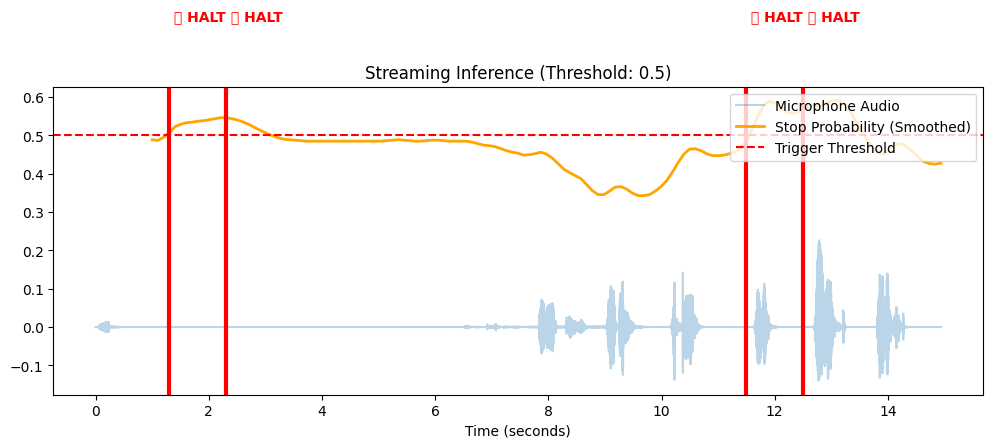

In [ ]:
def streaming_inference(wav_file, threshold=0.7):
    sample_rate, audio = wav.read(wav_file)
    audio = audio.astype(np.float32) / 32768.0 # Normalize to [-1, 1]

    window_size = 16000 # 1 second
    stride = 1600       # 100 ms

    preds_history = collections.deque(maxlen=3)
    refractory_counter = 0
    stop_scores = []
    events = []

    total_frames = (len(audio) - window_size) // stride

    print("\n--- Factory Floor Live Feed ---")
    for i in range(total_frames):
        start = i * stride
        end = start + window_size
        chunk = audio[start:end]

        probs, _, _ = run_tflite_inference(chunk)
        stop_prob = probs[0] # Index 0 is 'stop'

        preds_history.append(stop_prob)
        smoothed_prob = np.mean(preds_history)
        stop_scores.append(smoothed_prob)

        # Decrement refractory counter
        if refractory_counter > 0:
            refractory_counter -= 1

        # Trigger condition
        if smoothed_prob > threshold and refractory_counter == 0:
            timestamp = end / sample_rate
            events.append(timestamp)
            print(f"[{timestamp:.1f}s] 🛑 BELT STOPPED (Confidence: {smoothed_prob*100:.1f}%)")
            refractory_counter = 10 # 10 strides = 1 second refractory period

    # Plotting the shift
    time_axis = np.arange(len(audio)) / sample_rate
    score_axis = np.linspace(1, len(audio)/sample_rate, len(stop_scores))

    plt.figure(figsize=(12, 4))
    plt.plot(time_axis, audio, alpha=0.3, label='Microphone Audio')
    plt.plot(score_axis, stop_scores, color='orange', linewidth=2, label='Stop Probability (Smoothed)')
    plt.axhline(threshold, color='red', linestyle='--', label='Trigger Threshold')

    for ev in events:
        plt.axvline(ev, color='red', linewidth=3)
        plt.text(ev, 0.8, ' 🛑 HALT', color='red', fontweight='bold')

    plt.title(f"Streaming Inference (Threshold: {threshold})")
    plt.xlabel("Time (seconds)")
    plt.legend(loc='upper right')
    plt.show()

# Run the stream on your recorded audio
streaming_inference("work_shift.wav", threshold=0.5)